In [2]:
# import sympy
from sympy import (symbols, expand, Rational, init_printing, sqrt, cos, sin,
                   init_printing, pprint, simplify, factor, trigsimp, collect,
                   cancel, powsimp, expand_power_exp, powdenest)
init_printing()

x, y, z = symbols("x y z")

expr = x + 2*y
e2 = 3*x + y**2
e3 = expr*e2*z
e4 = expand(e3)
# # print(e3)
e4
# print((cos(x)+2).subs(cos(x), 3))


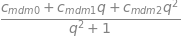

In [3]:
"""Calculations for m^-"""
x_0, y_0, theta0, x_c, y_c, r_c, rho, x_f, y_f, q = symbols(
    "x_0, y_0, theta0, x_c, y_c, r_c, rho, x_f, y_f, q")

R = r_c + rho
# print(R)

c_0x = x_0 + rho*sin(theta0)
c_0y = y_0 - rho*cos(theta0)

cos1 = (1 - q**2)/(1 + q**2)
sin1 = 2*q/(1 + q**2)

c_1x = x_c - R*sin1
c_1y = y_c + R*cos1

# m_minus_x and m_minus_y are MOST DEFINITELY NOT THE RIGHT VALUES HERE.
# I will need to look at how to make it all work. Maybe start from the end
# (end = developed theorem) and work towards the beginning?

m_minus_x = c_1x - c_0x
m_minus_x = collect(factor(m_minus_x), q)
m_minus_y = c_1y - c_0y
m_minus_y = collect(factor(m_minus_y),q)
# print("m_minus_x =", m_minus_x)
# print("m_minus_y =", m_minus_y)

m_d_minus = factor(m_minus_x**2 + m_minus_y**2)
m_d_minus = collect(m_d_minus, q)

# Simplify m_d_minus by regrouping some constant terms into subterms
m_d_minus_numer, m_d_minus_denom = m_d_minus.as_numer_denom()
# m_d_minus_numer
# m_d_minus_denom
# m_d_minus == m_d_minus_numer/m_d_minus_denom
c_mdm2, c_mdm1, c_mdm0 = symbols("c_mdm2, c_mdm1, c_mdm0")
c_md_min2 = m_d_minus_numer.coeff(q,2)
c_md_min1 = m_d_minus_numer.coeff(q,1)
c_md_min0 = m_d_minus_numer.coeff(q,0)
# m_d_minus_numer = m_d_minus_numer - c_md_min2*q**2 - c_md_min1*q - c_md_min0 + c_mdm2*q**2 + c_mdm1*q + c_mdm0
substitutions = dict(zip([c_md_min2, c_md_min1, c_md_min0], [c_mdm2, c_mdm1, c_mdm0]))
m_d_minus_numer = m_d_minus_numer.subs(substitutions)

# m_d_minus_numer
# c_md_min2
m_d_minus = m_d_minus_numer/m_d_minus_denom
# m_d_minus

m_d_minus
# m_minus_x
# m_minus_y

# print(c_md_min2)
# print(c_md_min1)
# print(c_md_min0)

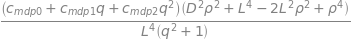

In [10]:
"""Calculations for m^+"""

# sin_thet, cos_thet, sin_delt, cos_delt = symbols("sin_thet, cos_thet, sin_delt, cos_delt")
L = sqrt( (c_1x - x_f)**2 + (c_1y - y_f)**2 )
L = expand(L)
L = symbols("L")
D = sqrt(L**2 - rho**2)
D = symbols('D')


sin_thet = D/L
# print(sin_thet)
cos_thet = rho/L
sin_delt = (y_f - c_1y)/L
# sin_delt = expand(sin_delt)
cos_delt = (x_f - c_1x)/L

x_L = c_1x + rho*(cos_delt*cos_thet + sin_delt*sin_thet)
y_L = c_1y + rho*(sin_delt*cos_thet - cos_delt*sin_thet)

m_plus_x = x_f - x_L
m_plus_x = factor(m_plus_x)
m_plus_x = collect(m_plus_x, [D, L])
m_plus_y = y_f - y_L
m_plus_y = factor(m_plus_y)
m_plus_y = collect(m_plus_y, [D, L])

m_d_plus = m_plus_x**2 + m_plus_y**2
m_d_plus = factor(m_d_plus)
m_d_plus = collect(m_d_plus, q)

# Simplify m_d_plus by regrouping some constant terms into subterms
m_d_plus_numer, m_d_plus_denom = m_d_plus.as_numer_denom()
# m_d_plus_numer
# m_d_plus_denom
m_d_plus_coeff = D**2*rho**2 + L**4 - 2*L**2*rho**2 + rho**4
m_d_plus_numer_simpl = m_d_plus_numer/m_d_plus_coeff
m_d_plus_numer_simpl
c_mdp2, c_mdp1, c_mdp0 = symbols("c_mdp2, c_mdp1, c_mdp0")
c_md_plus2 = m_d_plus_numer_simpl.coeff(q,2)
c_md_plus1 = m_d_plus_numer_simpl.coeff(q,1)
c_md_plus0 = m_d_plus_numer_simpl.coeff(q,0)
# c_md_plus2
# c_md_plus1
# c_md_plus0
substitutions = dict(zip([c_md_plus2, c_md_plus1, c_md_plus0], [c_mdp2, c_mdp1, c_mdp0]))
m_d_plus_numer = m_d_plus_numer.subs(substitutions)
m_d_plus = m_d_plus_numer/m_d_plus_denom
m_d_plus

# m_plus_x
# m_plus_y
# m_d_plus

# print(c_md_plus2)
# print(c_md_plus1)
# print(c_md_plus0)

In [5]:
"""Prepare the Ls and Ds before substituting them in the formula"""

# Manage L**2, denom = (q**2 + 1)
L_2 = factor((c_1x - x_f)**2 + (c_1y - y_f)**2)
L_2 = collect(L_2, q)
L_2_numer, L_2_denom = L_2.as_numer_denom()
c_L20, c_L21, c_L22 = symbols("c_L20, c_L21, c_L22")
c_L20_t = L_2_numer.coeff(q, 0)
c_L21_t = L_2_numer.coeff(q, 1)
c_L22_t = L_2_numer.coeff(q, 2)
substitutions_3 = dict(zip([c_L20_t, c_L21_t, c_L22_t], [c_L20, c_L21, c_L22]))
L_2_numer = L_2_numer.subs(substitutions_3)
L_2 = L_2_numer/L_2_denom

# Manage L**4, denom = (q**2 + 1)**2
L_4 = factor(expand(L_2**2))
L_4_numer, L_4_denom = L_4.as_numer_denom()
L_4_numer = collect(expand(L_4_numer), q)
# L_4_denom = expand(L_4_denom)
L_4 = L_4_numer/L_4_denom

# Manage L**6, denom = (q**2 + 1)**3
L_6 = factor(expand(L_2**3))
L_6_numer, L_6_denom = L_6.as_numer_denom()
L_6_numer = collect(expand(L_6_numer), q)
L_6 = L_6_numer/L_6_denom

# Manage L**8, denom = (q**2 + 1)**4
L_8 = factor(expand(L_2**4))
L_8_numer, L_8_denom = L_8.as_numer_denom()
L_8_numer = collect(expand(L_8_numer), q)
L_8 = L_8_numer/L_8_denom

# Manage D**2, denom = (q**2 + 1)
D_2 = L_2 - rho**2
D_2_numer, D_2_denom = D_2.as_numer_denom()
D_2_numer = collect(expand(D_2_numer), q)
D_2 = D_2_numer/D_2_denom
# D_2 = factor((L_2 - rho**2)*(q**2+1))

# Manage D**4, denom = (q**2 + 1)**2
D_4 = factor(expand(D_2**2))
D_4_numer, D_4_denom = D_4.as_numer_denom()
D_4_numer = collect(expand(D_4_numer), q)
D_4 = D_4_numer/D_4_denom

# L_2
# L_2_numer
# L_2_denom
# L_4
# L_6
# L_8
# L_4_numer
# L_4_denom
# D_2
# D_2_numer
# D_2_denom
# D_4

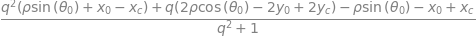

In [ ]:
"""Start combining everything to get to equation 55"""

v_tx = cos1
v_ty = sin1

c_s1 = v_tx*m_minus_x + v_ty*m_minus_y
c_s1 = collect(factor(expand(c_s1)), q)
c_s2 = v_tx*2*rho*m_minus_y - v_ty*2*rho*m_minus_x
c_s2 = collect(factor(expand(c_s2)), q)
c_s3 = v_tx*m_plus_x*m_d_minus + v_ty*m_plus_y*m_d_minus # Contains D not squared
c_s3 = collect(factor(expand(c_s3)), [L,D,q])

# c_s1
# c_s2
# c_s3

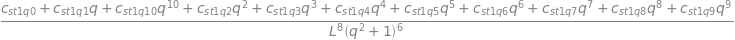

In [ ]:
### Manage c_st1

c_st1 = 2*c_s1*c_s2*m_d_plus
c_st1_num, c_st1_denom = c_st1.as_numer_denom()
c_st1_num = collect(expand(c_st1_num), [L,D,q])

# Replace D**2, L**2 and L**4 with their respective values
c_st1_num = c_st1_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
c_st1_num = factor(c_st1_num)
c_st1_num_num, c_st1_num_denom = c_st1_num.as_numer_denom()
c_st1_num_num = collect(expand(c_st1_num_num), q)

# Assemble the coefficients of the qs
c_st1_q0, c_st1_q1, c_st1_q2, c_st1_q3, c_st1_q4, c_st1_q5, c_st1_q6, c_st1_q7, c_st1_q8, c_st1_q9, c_st1_q10 = symbols(
    "c_st1_q0, c_st1_q1, c_st1_q2, c_st1_q3, c_st1_q4, c_st1_q5, c_st1_q6, c_st1_q7, c_st1_q8, c_st1_q9, c_st1_q10")
c_st1_q0t = c_st1_num_num.coeff(q,0)
c_st1_q1t = c_st1_num_num.coeff(q,1)
c_st1_q2t = c_st1_num_num.coeff(q,2)
c_st1_q3t = c_st1_num_num.coeff(q,3)
c_st1_q4t = c_st1_num_num.coeff(q,4)
c_st1_q5t = c_st1_num_num.coeff(q,5)
c_st1_q6t = c_st1_num_num.coeff(q,6)
c_st1_q7t = c_st1_num_num.coeff(q,7)
c_st1_q8t = c_st1_num_num.coeff(q,8)
c_st1_q9t = c_st1_num_num.coeff(q,9)
c_st1_q10t = c_st1_num_num.coeff(q,10)
subs = dict(zip([c_st1_q0t, c_st1_q1t, c_st1_q2t, c_st1_q3t, c_st1_q4t, c_st1_q5t, c_st1_q6t, c_st1_q7t, c_st1_q8t, c_st1_q9t, c_st1_q10t],
                [c_st1_q0, c_st1_q1, c_st1_q2, c_st1_q3, c_st1_q4, c_st1_q5, c_st1_q6, c_st1_q7, c_st1_q8, c_st1_q9, c_st1_q10]))
c_st1_num_num = c_st1_num_num.subs(subs)
c_st1_num = c_st1_num_num/c_st1_denom

# Get c_st1 back to its full form
c_st1 = c_st1_num/c_st1_denom

c_st1
# c_st1_num
# c_st1_num.coeff(L,2)
# c_st1_q1

# c_st1_num_num
# c_st1_num_denom

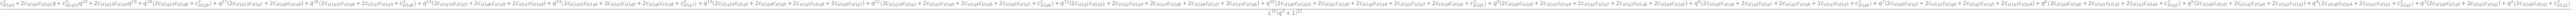

In [ ]:
################ Square up that term!#################
c_st1_2 = c_st1**2
c_st1_2_num, c_st1_2_denom = c_st1_2.as_numer_denom()
c_st1_2_num = collect(expand(c_st1_2_num), [L,D,q])
# c_st1_2_num = collect(factor(expand(c_st1_2_num)), [L,D,q])


# Bring the term back together
c_st1_2 = c_st1_2_num/c_st1_2_denom # order 20

# c_st1_2_num
c_st1_2



In [ ]:
### Multiply c_st1**2 with c_st2

c_st2 = collect(factor(m_d_minus - 4*rho), q)
c_stL = c_st1_2*c_st2
c_stL_num, c_stL_denom = c_stL.as_numer_denom()
c_stL_num = collect(expand(c_stL_num), q) # order 22


###########################
### PROBABLY COME BACK LATER TO ASSEMBLE TERMS
###########################

c_stL = c_stL_num/c_stL_denom

# c_st2
c_stL
# c_stL_num

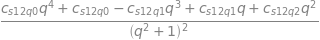

In [129]:
### Square c_s1

c_s1 = v_tx*m_minus_x + v_ty*m_minus_y
c_s1 = collect(factor(expand(c_s1)), q)

c_s1_2 = c_s1**2
c_s1_2_num, c_s1_2_denom = c_s1_2.as_numer_denom()
c_s1_2_num = collect(expand(c_s1_2_num), q)

c_s1_2_q0, c_s1_2_q1, c_s1_2_q2 = symbols(
    "c_s1_2_q0, c_s1_2_q1, c_s1_2_q2")
c_s1_2_q0t = c_s1_2_num.coeff(q,0)
c_s1_2_q1t = c_s1_2_num.coeff(q,1)
c_s1_2_q2t = c_s1_2_num.coeff(q,2)
subs = dict(zip([c_s1_2_q1t, c_s1_2_q2t, c_s1_2_q0t],
                [c_s1_2_q1, c_s1_2_q2, c_s1_2_q0]))
c_s1_2_num = c_s1_2_num.subs(subs) # order 4, but terms 3 and 4 are the same as -1 and 0.

c_s1_2 = c_s1_2_num/c_s1_2_denom

# c_s1
c_s1_2
# c_s1_2_num
# c_s1_2_denom

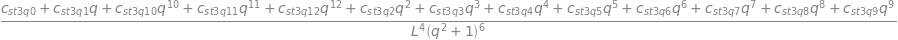

In [130]:
### Manage c_st3

c_st3 = c_s1_2*c_st2*m_d_plus
c_st3_num, c_st3_denom = c_st3.as_numer_denom()

# Replace D**2, L**2 and L**4 with their respective values
c_st3_num = c_st3_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
c_st3_num = factor(c_st3_num)
c_st3_num_num, c_st3_num_denom = c_st3_num.as_numer_denom()
c_st3_num_num = collect(expand(c_st3_num_num), q) # looks like order 12

# Assemble the coefficients of the qs
c_st3_q0, c_st3_q1, c_st3_q2, c_st3_q3, c_st3_q4, c_st3_q5, c_st3_q6, c_st3_q7, c_st3_q8, c_st3_q9, c_st3_q10, c_st3_q11, c_st3_q12 = symbols(
    "c_st3_q0, c_st3_q1, c_st3_q2, c_st3_q3, c_st3_q4, c_st3_q5, c_st3_q6, c_st3_q7, c_st3_q8, c_st3_q9, c_st3_q10, c_st3_q11, c_st3_q12")
c_st3_q0t = c_st3_num_num.coeff(q,0)
c_st3_q1t = c_st3_num_num.coeff(q,1)
c_st3_q2t = c_st3_num_num.coeff(q,2)
c_st3_q3t = c_st3_num_num.coeff(q,3)
c_st3_q4t = c_st3_num_num.coeff(q,4)
c_st3_q5t = c_st3_num_num.coeff(q,5)
c_st3_q6t = c_st3_num_num.coeff(q,6)
c_st3_q7t = c_st3_num_num.coeff(q,7)
c_st3_q8t = c_st3_num_num.coeff(q,8)
c_st3_q9t = c_st3_num_num.coeff(q,9)
c_st3_q10t = c_st3_num_num.coeff(q,10)
c_st3_q11t = c_st3_num_num.coeff(q,11)
c_st3_q12t = c_st3_num_num.coeff(q,12)
subs = dict(zip([c_st3_q0t, c_st3_q1t, c_st3_q2t, c_st3_q3t, c_st3_q4t, c_st3_q5t, c_st3_q6t, c_st3_q7t, c_st3_q8t, c_st3_q9t, c_st3_q10t, c_st3_q11t, c_st3_q12t],
                [c_st3_q0, c_st3_q1, c_st3_q2, c_st3_q3, c_st3_q4, c_st3_q5, c_st3_q6, c_st3_q7, c_st3_q8, c_st3_q9, c_st3_q10, c_st3_q11, c_st3_q12]))
c_st3_num_num = c_st3_num_num.subs(subs)
c_st3_num = c_st3_num_num/c_st3_num_denom

c_st3 = c_st3_num/c_st3_denom

# c_st2
c_st3
# c_st3_num

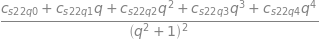

In [131]:
### Square c_s2

c_s2 = v_tx*2*rho*m_minus_y - v_ty*2*rho*m_minus_x
c_s2 = collect(factor(expand(c_s2)), q)

c_s2_2 = c_s2**2
c_s2_2_num, c_s2_2_denom = c_s2_2.as_numer_denom()
c_s2_2_num = collect(expand(c_s2_2_num), q)
c_s2_2_q0, c_s2_2_q1, c_s2_2_q2, c_s2_2_q3, c_s2_2_q4 = symbols(
    "c_s2_2_q0, c_s2_2_q1, c_s2_2_q2, c_s2_2_q3, c_s2_2_q4")
c_s2_2_q0t = c_s2_2_num.coeff(q,0)
c_s2_2_q1t = c_s2_2_num.coeff(q,1)
c_s2_2_q2t = c_s2_2_num.coeff(q,2)
c_s2_2_q3t = c_s2_2_num.coeff(q,3)
c_s2_2_q4t = c_s2_2_num.coeff(q,4)
subs = dict(zip([c_s2_2_q0t, c_s2_2_q1t, c_s2_2_q2t, c_s2_2_q3t, c_s2_2_q4t],
                [c_s2_2_q0, c_s2_2_q1, c_s2_2_q2, c_s2_2_q3, c_s2_2_q4]))
c_s2_2_num = c_s2_2_num.subs(subs) # order 4, but terms 3 and 4 are the same as -1 and 0.

c_s2_2 = c_s2_2_num/c_s2_2_denom




# c_s2_2_num
c_s2_2

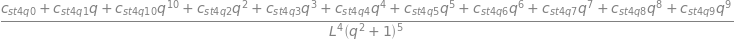

In [132]:
### Manage c_st4

c_st4 = c_s2_2*m_d_plus
c_st4_num, c_st4_denom = c_st4.as_numer_denom()

# Replace D**2, L**2 and L**4 with their respective values
c_st4_num = c_st4_num.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
c_st4_num = factor(c_st4_num)
c_st4_num_num, c_st4_num_denom = c_st4_num.as_numer_denom()
c_st4_num_num = collect(expand(c_st4_num_num), q) # looks like order 12

# # Assemble the coefficients of the qs
c_st4_q0, c_st4_q1, c_st4_q2, c_st4_q3, c_st4_q4, c_st4_q5, c_st4_q6, c_st4_q7, c_st4_q8, c_st4_q9, c_st4_q10 = symbols(
    "c_st4_q0, c_st4_q1, c_st4_q2, c_st4_q3, c_st4_q4, c_st4_q5, c_st4_q6, c_st4_q7, c_st4_q8, c_st4_q9, c_st4_q10")
c_st4_q0t = c_st4_num_num.coeff(q,0)
c_st4_q1t = c_st4_num_num.coeff(q,1)
c_st4_q2t = c_st4_num_num.coeff(q,2)
c_st4_q3t = c_st4_num_num.coeff(q,3)
c_st4_q4t = c_st4_num_num.coeff(q,4)
c_st4_q5t = c_st4_num_num.coeff(q,5)
c_st4_q6t = c_st4_num_num.coeff(q,6)
c_st4_q7t = c_st4_num_num.coeff(q,7)
c_st4_q8t = c_st4_num_num.coeff(q,8)
c_st4_q9t = c_st4_num_num.coeff(q,9)
c_st4_q10t = c_st4_num_num.coeff(q,10)
subs = dict(zip([c_st4_q0t, c_st4_q1t, c_st4_q2t, c_st4_q3t, c_st4_q4t, c_st4_q5t, c_st4_q6t, c_st4_q7t, c_st4_q8t, c_st4_q9t, c_st4_q10t],
                [c_st4_q0, c_st4_q1, c_st4_q2, c_st4_q3, c_st4_q4, c_st4_q5, c_st4_q6, c_st4_q7, c_st4_q8, c_st4_q9, c_st4_q10]))
c_st4_num_num = c_st4_num_num.subs(subs)
c_st4_num = c_st4_num_num/c_st4_num_denom

c_st4 = c_st4_num/c_st4_denom

c_st4
# m_d_plus

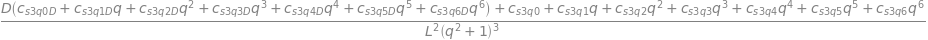

In [200]:
### Manage c_s3

c_s3 = v_tx*m_plus_x*m_d_minus + v_ty*m_plus_y*m_d_minus # Contains D not squared
c_s3 = collect(factor(expand(c_s3)), [L,D,q])

# Replace L**2 by its respective value
c_s3_num, c_s3_denom = c_s3.as_numer_denom()
c_s3_num = c_s3_num.xreplace({L**2: L_2})
c_s3_num = factor(c_s3_num)
c_s3_num_num, c_s3_num_denom = c_s3_num.as_numer_denom()
c_s3_num_num = expand(c_s3_num_num)
c_s3_num_num = collect(c_s3_num_num, [D,q])

# Assemble sub-terms NOT multiplied by D
c_s3_q0, c_s3_q1, c_s3_q2, c_s3_q3, c_s3_q4, c_s3_q5, c_s3_q6 = symbols(
    "c_s3_q0, c_s3_q1, c_s3_q2, c_s3_q3, c_s3_q4, c_s3_q5, c_s3_q6")
c_s3_q0t = c_s3_num_num.coeff(D,0).coeff(q,0)
c_s3_q1t = c_s3_num_num.coeff(D,0).coeff(q,1)
c_s3_q2t = c_s3_num_num.coeff(D,0).coeff(q,2)
c_s3_q3t = c_s3_num_num.coeff(q,3)
c_s3_q4t = c_s3_num_num.coeff(q,4)
c_s3_q5t = c_s3_num_num.coeff(q,5)
c_s3_q6t = c_s3_num_num.coeff(q,6)
subs = dict(zip([c_s3_q0t, c_s3_q1t, c_s3_q2t, c_s3_q3t, c_s3_q4t, c_s3_q5t, c_s3_q6t],
                [c_s3_q0, c_s3_q1, c_s3_q2, c_s3_q3, c_s3_q4, c_s3_q5, c_s3_q6]))
c_s3_num_num = c_s3_num_num.subs(subs)

# Assemble sub-terms multiplied by D
D_term = c_s3_num_num.coeff(D,1)
D_term = collect(D_term, q)
c_s3_q0D, c_s3_q1D, c_s3_q2D, c_s3_q3D, c_s3_q4D, c_s3_q5D, c_s3_q6D = symbols(
    "c_s3_q0D, c_s3_q1D, c_s3_q2D, c_s3_q3D, c_s3_q4D, c_s3_q5D, c_s3_q6D")
c_s3_q0Dt = c_s3_num_num.coeff(D,1).coeff(q,0)
c_s3_q1Dt = c_s3_num_num.coeff(D,1).coeff(q,1)
c_s3_q2Dt = c_s3_num_num.coeff(D,1).coeff(q,2)
c_s3_q3Dt = c_s3_num_num.coeff(D,1).coeff(q,3)
c_s3_q4Dt = c_s3_num_num.coeff(D,1).coeff(q,4)
c_s3_q5Dt = c_s3_num_num.coeff(D,1).coeff(q,5)
c_s3_q6Dt = c_s3_num_num.coeff(D,1).coeff(q,6)
subs = dict(zip([c_s3_q0Dt, c_s3_q1Dt, c_s3_q2Dt, c_s3_q3Dt, c_s3_q4Dt, c_s3_q5Dt, c_s3_q6Dt],
                [c_s3_q0D, c_s3_q1D, c_s3_q2D, c_s3_q3D, c_s3_q4D, c_s3_q5D, c_s3_q6D]))
D_term = D_term.subs(subs)

# Replace the old term in D by the new term with assembled coefficients
c_s3_num = (c_s3_num_num - D*c_s3_num_num.coeff(D,1) + D*D_term)/c_s3_num_denom
c_s3 = c_s3_num/c_s3_denom

c_s3
# c_s3_num
# c_s3_num_num
# c_s3_denom
# L_2
# c_s3_q1t
# c_s3_q6Dt
# D_term

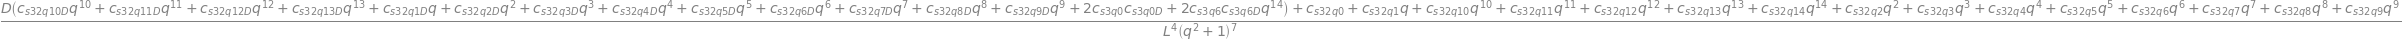

In [213]:
### Square c_s3

c_s3_2 = c_s3**2
c_s3_2_num, c_s3_2_denom = c_s3_2.as_numer_denom()
c_s3_2_num = collect(expand(c_s3_2_num), [D,q])

# Replace D**2 by its value
c_s3_2_num = c_s3_2_num.xreplace({D**2: D_2})
# c_s3_2_num = factor(c_s3_2_num)
c_s3_2_num_num, c_s3_2_num_denom = c_s3_2_num.as_numer_denom()
c_s3_2_num_num = expand(c_s3_2_num_num)
c_s3_2_num_num = collect(c_s3_2_num_num, [D,q])

# Assemble sub-terms NOT multiplied by D
c_s3_2_q0, c_s3_2_q1, c_s3_2_q2, c_s3_2_q3, c_s3_2_q4, c_s3_2_q5, c_s3_2_q6, c_s3_2_q7, c_s3_2_q8, c_s3_2_q9, c_s3_2_q10, c_s3_2_q11, c_s3_2_q12, c_s3_2_q13, c_s3_2_q14 = symbols(
    "c_s3_2_q0, c_s3_2_q1, c_s3_2_q2, c_s3_2_q3, c_s3_2_q4, c_s3_2_q5, c_s3_2_q6, c_s3_2_q7, c_s3_2_q8, c_s3_2_q9, c_s3_2_q10, c_s3_2_q11, c_s3_2_q12, c_s3_2_q13, c_s3_2_q14")
c_s3_2_q0t = c_s3_2_num_num.coeff(q,0)
c_s3_2_q1t = c_s3_2_num_num.coeff(q,1)
c_s3_2_q2t = c_s3_2_num_num.coeff(q,2)
c_s3_2_q3t = c_s3_2_num_num.coeff(q,3)
c_s3_2_q4t = c_s3_2_num_num.coeff(q,4)
c_s3_2_q5t = c_s3_2_num_num.coeff(q,5)
c_s3_2_q6t = c_s3_2_num_num.coeff(q,6)
c_s3_2_q7t = c_s3_2_num_num.coeff(q,7)
c_s3_2_q8t = c_s3_2_num_num.coeff(q,8)
c_s3_2_q9t = c_s3_2_num_num.coeff(q,9)
c_s3_2_q10t = c_s3_2_num_num.coeff(q,10)
c_s3_2_q11t = c_s3_2_num_num.coeff(q,11)
c_s3_2_q12t = c_s3_2_num_num.coeff(q,12)
c_s3_2_q13t = c_s3_2_num_num.coeff(q,13)
c_s3_2_q14t = c_s3_2_num_num.coeff(q,14)
subs = dict(zip([c_s3_2_q0t, c_s3_2_q1t, c_s3_2_q2t, c_s3_2_q3t, c_s3_2_q4t, c_s3_2_q5t, c_s3_2_q6t, c_s3_2_q7t, c_s3_2_q8t, c_s3_2_q9t, c_s3_2_q10t, c_s3_2_q11t, c_s3_2_q12t, c_s3_2_q13t, c_s3_2_q14t],
                [c_s3_2_q0, c_s3_2_q1, c_s3_2_q2, c_s3_2_q3, c_s3_2_q4, c_s3_2_q5, c_s3_2_q6, c_s3_2_q7, c_s3_2_q8, c_s3_2_q9, c_s3_2_q10, c_s3_2_q11, c_s3_2_q12, c_s3_2_q13, c_s3_2_q14]))
c_s3_2_num_num = c_s3_2_num_num.subs(subs)

# Assemble sub-terms multiplied by D
D_term = c_s3_2_num_num.coeff(D,1)
D_term = collect(D_term, q)
c_s3_2_q1D, c_s3_2_q2D, c_s3_2_q3D, c_s3_2_q4D, c_s3_2_q5D, c_s3_2_q6D, c_s3_2_q7D, c_s3_2_q8D, c_s3_2_q9D, c_s3_2_q10D, c_s3_2_q11D, c_s3_2_q12D, c_s3_2_q13D = symbols(
    "c_s3_2_q1D, c_s3_2_q2D, c_s3_2_q3D, c_s3_2_q4D, c_s3_2_q5D, c_s3_2_q6D, c_s3_2_q7D, c_s3_2_q8D, c_s3_2_q9D, c_s3_2_q10D, c_s3_2_q11D, c_s3_2_q12D, c_s3_2_q13D")
c_s3_2_q1Dt = c_s3_2_num_num.coeff(D,1).coeff(q,1)
c_s3_2_q2Dt = c_s3_2_num_num.coeff(D,1).coeff(q,2)
c_s3_2_q3Dt = c_s3_2_num_num.coeff(D,1).coeff(q,3)
c_s3_2_q4Dt = c_s3_2_num_num.coeff(D,1).coeff(q,4)
c_s3_2_q5Dt = c_s3_2_num_num.coeff(D,1).coeff(q,5)
c_s3_2_q6Dt = c_s3_2_num_num.coeff(D,1).coeff(q,6)
c_s3_2_q7Dt = c_s3_2_num_num.coeff(D,1).coeff(q,7)
c_s3_2_q8Dt = c_s3_2_num_num.coeff(D,1).coeff(q,8)
c_s3_2_q9Dt = c_s3_2_num_num.coeff(D,1).coeff(q,9)
c_s3_2_q10Dt = c_s3_2_num_num.coeff(D,1).coeff(q,10)
c_s3_2_q11Dt = c_s3_2_num_num.coeff(D,1).coeff(q,11)
c_s3_2_q12Dt = c_s3_2_num_num.coeff(D,1).coeff(q,12)
c_s3_2_q13Dt = c_s3_2_num_num.coeff(D,1).coeff(q,13)
subs = dict(zip([c_s3_2_q1Dt, c_s3_2_q2Dt, c_s3_2_q3Dt, c_s3_2_q4Dt, c_s3_2_q5Dt, c_s3_2_q6Dt, c_s3_2_q7Dt, c_s3_2_q8Dt, c_s3_2_q9Dt, c_s3_2_q10Dt, c_s3_2_q11Dt, c_s3_2_q12Dt, c_s3_2_q13Dt],
                [c_s3_2_q1D, c_s3_2_q2D, c_s3_2_q3D, c_s3_2_q4D, c_s3_2_q5D, c_s3_2_q6D, c_s3_2_q7D, c_s3_2_q8D, c_s3_2_q9D, c_s3_2_q10D, c_s3_2_q11D, c_s3_2_q12D, c_s3_2_q13D]))
D_term = D_term.subs(subs)



# Replace the old term in D by the new term with assembled coefficients
c_s3_2_num_num = c_s3_2_num_num - D*c_s3_2_num_num.coeff(D,1) + D*D_term

c_s3_2_num = c_s3_2_num_num/c_s3_2_num_denom
c_s3_2 = c_s3_2_num/c_s3_2_denom

c_s3_2
# c_s3_2_num
# c_s3_2_num_num
# D_term
# c_s3_2_num_denom

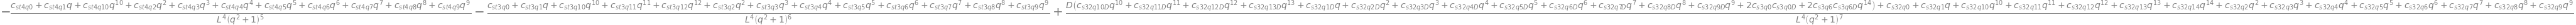

In [215]:
### Square the right side of the equality in eq 59

c_stR = c_s3_2 - c_st3 - c_st4

c_stR

In [85]:
##################### where I'm at #################################

In [ ]:
"""Combining m^- and m^+"""

v_tx = cos1
v_ty = sin1

side1 = (v_tx*m_minus_x + v_ty*m_minus_y)**2
side1_numer, side1_denom = side1.as_numer_denom()
side1_numer = collect(expand(side1_numer), q)
side1 = side1_numer/side1_denom
# side1_numer
# side1_denom
# side1

all_side1 = side1*m_d_plus
all_side1_numer, all_side1_denom = all_side1.as_numer_denom()

# all_side1_denom

In [ ]:
"""Combining m^- and m^+, second side of eq 38"""

v_tx = cos1
v_ty = sin1

side2 = (v_tx*m_plus_x + v_ty*m_plus_y)**2
side2_numer, side2_denom = side2.as_numer_denom()
side2_numer = collect(expand(side2_numer), [D, q])
side2 = side2_numer/side2_denom
# side2_denom

all_side2 = side2*m_d_minus
all_side2_numer, all_side2_denom = all_side2.as_numer_denom()

# all_side2_denom

In [ ]:
"""Combine both sides of the equality"""
# Both sides of eq 38 have the same denominator, so we can cancel it.

side_1_ = all_side1_numer
side_2_ = all_side2_numer

comb = side_1_ - side_2_
comb = collect(expand(comb), [D, q])
# comb = collect(comb, D)

# Isolate the term in D
D_term = comb.coeff(D, 1)
# D_term = collect(D_term, [L, q])
# print(comb)

# Remove the D_term to isolate it
comb_without_D = comb - D*D_term
comb_without_D = collect(comb_without_D, [L,D,q])

# Simplify the D-less term a bit
c_nd_L2, c_nd_L4, c_nd_0 = symbols("c_nd_L2, c_nd_L4, c_nd_0")
c_nd_L2_t = comb_without_D.coeff(L, 2) # constant term multiplying L**2
c_nd_L4_t = comb_without_D.coeff(L, 4) # constant term multiplying L**4
c_nd_0_t = comb_without_D.coeff(L,0).coeff(q,0).coeff(D,0) # constant term multiplying nothing!
comb_without_D = comb_without_D.subs({c_nd_L2_t: c_nd_L2, c_nd_L4_t: c_nd_L4, c_nd_0_t: c_nd_0})

# Simplify the q coefficients that are multiplied by L**4 in the D-less term
c_q1_L4, c_q2_L4, c_q3_L4, c_q4_L4, c_q5_L4, c_q6_L4, c_q7_L4, c_q8_L4, c_q9_L4, c_q10_L4 = symbols(
    "c_q1_L4, c_q2_L4, c_q3_L4, c_q4_L4, c_q5_L4, c_q6_L4, c_q7_L4, c_q8_L4, c_q9_L4, c_q10_L4")
c_q1_L4_t = comb_without_D.coeff(q,1).coeff(L,4)
c_q2_L4_t = comb_without_D.coeff(q,2).coeff(L,4)
c_q3_L4_t = comb_without_D.coeff(q,3).coeff(L,4)
c_q4_L4_t = comb_without_D.coeff(q,4).coeff(L,4)
c_q5_L4_t = comb_without_D.coeff(q,5).coeff(L,4)
c_q6_L4_t = comb_without_D.coeff(q,6).coeff(L,4)
c_q7_L4_t = comb_without_D.coeff(q,7).coeff(L,4)
c_q8_L4_t = comb_without_D.coeff(q,8).coeff(L,4)
c_q9_L4_t = comb_without_D.coeff(q,9).coeff(L,4)
c_q10_L4_t = comb_without_D.coeff(q,10).coeff(L,4)
substitutions_4 = dict(zip([c_q1_L4_t, c_q2_L4_t, c_q3_L4_t, c_q4_L4_t, c_q5_L4_t, c_q6_L4_t, c_q7_L4_t, c_q8_L4_t, c_q9_L4_t, c_q10_L4_t],
                           [c_q1_L4, c_q2_L4, c_q3_L4, c_q4_L4, c_q5_L4, c_q6_L4, c_q7_L4, c_q8_L4, c_q9_L4, c_q10_L4]))
comb_without_D = comb_without_D.subs(substitutions_4)

# Simplify the q coefficients that are multiplied by L**2 in the D-less term
c_q1_L2, c_q2_L2, c_q3_L2, c_q4_L2, c_q5_L2, c_q6_L2, c_q7_L2, c_q8_L2, c_q9_L2, c_q10_L2 = symbols(
    "c_q1_L2, c_q2_L2, c_q3_L2, c_q4_L2, c_q5_L2, c_q6_L2, c_q7_L2, c_q8_L2, c_q9_L2, c_q10_L2")
c_q1_L2_t = comb_without_D.coeff(q,1).coeff(L,2)
c_q2_L2_t = comb_without_D.coeff(q,2).coeff(L,2)
c_q3_L2_t = comb_without_D.coeff(q,3).coeff(L,2)
c_q4_L2_t = comb_without_D.coeff(q,4).coeff(L,2)
c_q5_L2_t = comb_without_D.coeff(q,5).coeff(L,2)
c_q6_L2_t = comb_without_D.coeff(q,6).coeff(L,2)
c_q7_L2_t = comb_without_D.coeff(q,7).coeff(L,2)
c_q8_L2_t = comb_without_D.coeff(q,8).coeff(L,2)
c_q9_L2_t = comb_without_D.coeff(q,9).coeff(L,2)
c_q10_L2_t = comb_without_D.coeff(q,10).coeff(L,2)
substitutions_5 = dict(zip([c_q1_L2_t, c_q2_L2_t, c_q3_L2_t, c_q4_L2_t, c_q5_L2_t, c_q6_L2_t, c_q7_L2_t, c_q8_L2_t, c_q9_L2_t, c_q10_L2_t],
                           [c_q1_L2, c_q2_L2, c_q3_L2, c_q4_L2, c_q5_L2, c_q6_L2, c_q7_L2, c_q8_L2, c_q9_L2, c_q10_L2]))
comb_without_D = comb_without_D.subs(substitutions_5)

# Simplify the q coefficients that are multiplied by NOTHING in the D-less term
c_q1_L0, c_q2_L0, c_q3_L0, c_q4_L0, c_q5_L0, c_q6_L0, c_q7_L0, c_q8_L0, c_q9_L0, c_q10_L0 = symbols(
    "c_q1_L0, c_q2_L0, c_q3_L0, c_q4_L0, c_q5_L0, c_q6_L0, c_q7_L0, c_q8_L0, c_q9_L0, c_q10_L0")
c_q1_L0_t = comb_without_D.coeff(q,1).coeff(L,0)
c_q2_L0_t = comb_without_D.coeff(q,2).coeff(L,0)
c_q3_L0_t = comb_without_D.coeff(q,3).coeff(L,0)
c_q4_L0_t = comb_without_D.coeff(q,4).coeff(L,0)
c_q5_L0_t = comb_without_D.coeff(q,5).coeff(L,0)
c_q6_L0_t = comb_without_D.coeff(q,6).coeff(L,0)
c_q7_L0_t = comb_without_D.coeff(q,7).coeff(L,0)
c_q8_L0_t = comb_without_D.coeff(q,8).coeff(L,0)
c_q9_L0_t = comb_without_D.coeff(q,9).coeff(L,0)
c_q10_L0_t = comb_without_D.coeff(q,10).coeff(L,0)
substitutions_6 = dict(zip([c_q1_L0_t, c_q2_L0_t, c_q3_L0_t, c_q4_L0_t, c_q5_L0_t, c_q6_L0_t, c_q7_L0_t, c_q8_L0_t, c_q9_L0_t, c_q10_L0_t],
                           [c_q1_L0, c_q2_L0, c_q3_L0, c_q4_L0, c_q5_L0, c_q6_L0, c_q7_L0, c_q8_L0, c_q9_L0, c_q10_L0]))
comb_without_D = comb_without_D.subs(substitutions_6)

# Simplify the q coefficients that are multiplied by D**2 in the D-less term
c_q0_D2, c_q1_D2, c_q2_D2, c_q3_D2, c_q4_D2, c_q5_D2, c_q6_D2, c_q7_D2, c_q8_D2, c_q9_D2, c_q10_D2 = symbols(
    "c_q0_D2, c_q1_D2, c_q2_D2, c_q3_D2, c_q4_D2, c_q5_D2, c_q6_D2, c_q7_D2, c_q8_D2, c_q9_D2, c_q10_D2")
c_q0_D2_t = comb_without_D.coeff(D,2).coeff(q,0)
c_q1_D2_t = comb_without_D.coeff(D,2).coeff(q,1)
c_q2_D2_t = comb_without_D.coeff(D,2).coeff(q,2)
c_q3_D2_t = comb_without_D.coeff(D,2).coeff(q,3)
c_q4_D2_t = comb_without_D.coeff(D,2).coeff(q,4)
c_q5_D2_t = comb_without_D.coeff(D,2).coeff(q,5)
c_q6_D2_t = comb_without_D.coeff(D,2).coeff(q,6)
c_q7_D2_t = comb_without_D.coeff(D,2).coeff(q,7)
c_q8_D2_t = comb_without_D.coeff(D,2).coeff(q,8)
c_q9_D2_t = comb_without_D.coeff(D,2).coeff(q,9)
c_q10_D2_t = comb_without_D.coeff(D,2).coeff(q,10)
substitutions_7 = dict(zip([c_q0_D2_t, c_q1_D2_t, c_q2_D2_t, c_q3_D2_t, c_q4_D2_t, c_q5_D2_t, c_q6_D2_t, c_q7_D2_t, c_q8_D2_t, c_q9_D2_t, c_q10_D2_t],
                           [c_q0_D2, c_q1_D2, c_q2_D2, c_q3_D2, c_q4_D2, c_q5_D2, c_q6_D2, c_q7_D2, c_q8_D2, c_q9_D2, c_q10_D2]))
comb_without_D = comb_without_D.subs(substitutions_7)

# Simplify the D_term after removing it from the other term
D_term = collect(D_term, [L, q])
c_d_0, c_d_1, c_d_2, c_d_3, c_d_4, c_d_5, c_d_6, c_d_7, c_d_8, c_d_9, c_d_10 = symbols(
    "c_d_0, c_d_1, c_d_2, c_d_3, c_d_4, c_d_5, c_d_6, c_d_7, c_d_8, c_d_9, c_d_10")
c_d_0_t = D_term.coeff(q, 0)
c_d_1_t = D_term.coeff(q, 1)
c_d_2_t = D_term.coeff(q, 2)
c_d_3_t = D_term.coeff(q, 3)
c_d_4_t = D_term.coeff(q, 4)
c_d_5_t = D_term.coeff(q, 5)
c_d_6_t = D_term.coeff(q, 6)
c_d_7_t = D_term.coeff(q, 7)
c_d_8_t = D_term.coeff(q, 8)
c_d_9_t = D_term.coeff(q, 9)
c_d_10_t = D_term.coeff(q, 10)
substitutions_8 = dict(zip([c_d_0_t, c_d_1_t, c_d_2_t, c_d_3_t, c_d_4_t, c_d_5_t, c_d_6_t, c_d_7_t, c_d_8_t, c_d_9_t, c_d_10_t],
                           [c_d_0, c_d_1, c_d_2, c_d_3, c_d_4, c_d_5, c_d_6, c_d_7, c_d_8, c_d_9, c_d_10]))
D_term = D_term.subs(substitutions_8)

# Also simplify the q terms multiplied by L**2 in the D_term
D_term = collect(D_term, [L, q])
c_dL_0, c_dL_1, c_dL_2, c_dL_3, c_dL_4, c_dL_5, c_dL_6, c_dL_7, c_dL_8, c_dL_9, c_dL_10 = symbols(
    "c_dL_0, c_dL_1, c_dL_2, c_dL_3, c_dL_4, c_dL_5, c_dL_6, c_dL_7, c_dL_8, c_dL_9, c_dL_10")
c_dL_0_t = D_term.coeff(L,2).coeff(q, 0)
c_dL_1_t = D_term.coeff(L,2).coeff(q, 1)
c_dL_2_t = D_term.coeff(L,2).coeff(q, 2)
c_dL_3_t = D_term.coeff(L,2).coeff(q, 3)
c_dL_4_t = D_term.coeff(L,2).coeff(q, 4)
c_dL_5_t = D_term.coeff(L,2).coeff(q, 5)
c_dL_6_t = D_term.coeff(L,2).coeff(q, 6)
c_dL_7_t = D_term.coeff(L,2).coeff(q, 7)
c_dL_8_t = D_term.coeff(L,2).coeff(q, 8)
c_dL_9_t = D_term.coeff(L,2).coeff(q, 9)
c_dL_10_t = D_term.coeff(L,2).coeff(q, 10)
substitutions_9 = dict(zip([c_dL_0_t, c_dL_1_t, c_dL_2_t, c_dL_3_t, c_dL_4_t, c_dL_5_t, c_dL_6_t, c_dL_7_t, c_dL_8_t, c_dL_9_t, c_dL_10_t],
                           [c_dL_0, c_dL_1, c_dL_2, c_dL_3, c_dL_4, c_dL_5, c_dL_6, c_dL_7, c_dL_8, c_dL_9, c_dL_10]))
D_term = D_term.subs(substitutions_9)

# comb
# D_term.coeff(L,2)
# c_d_0_t
# comb_without_D # about 15s
# c_nd_L2_t
# c_nd_0_t
# c_q7_L4_t
# c_dL_10_t

# D_term

# print(c_nd_L2_t)
# print(c_nd_L4_t)
# print(c_nd_0_t)

# print(c_q1_L4_t)
# print(c_q2_L4_t)
# print(c_q3_L4_t)
# print(c_q4_L4_t)
# print(c_q5_L4_t)
# print(c_q6_L4_t)
# print(c_q7_L4_t)
# print(c_q8_L4_t)
# print(c_q9_L4_t)
# print(c_q10_L4_t)

In [ ]:
"""Square the D_term side of the equality."""

D_term_squared = D_term**2
D_term_final = D**2*D_term_squared
D_term_final = collect(expand(D_term_final), [D, L, q])
# D_term_squared
# D_term_final
# Contains D**2 and L**(2,4), multiplying each other

# Simplify the L**4 term in D_term_final
(c_q2_D2_L4,
c_q3_D2_L4,
c_q4_D2_L4,
c_q5_D2_L4,
c_q6_D2_L4,
c_q7_D2_L4,
c_q8_D2_L4,
c_q9_D2_L4,
c_q10_D2_L4,
c_q11_D2_L4,
c_q12_D2_L4,
c_q13_D2_L4,
c_q14_D2_L4,
c_q15_D2_L4,
c_q16_D2_L4,
c_q17_D2_L4,
c_q18_D2_L4) = symbols(
    "c_q2_D2_L4, c_q3_D2_L4, c_q4_D2_L4, c_q5_D2_L4, c_q6_D2_L4, c_q7_D2_L4, c_q8_D2_L4, c_q9_D2_L4, c_q10_D2_L4, c_q11_D2_L4, c_q12_D2_L4, c_q13_D2_L4, c_q14_D2_L4, c_q15_D2_L4, c_q16_D2_L4, c_q17_D2_L4, c_q18_D2_L4"
)
c_q2_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 2)
c_q3_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 3)
c_q4_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 4)
c_q5_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 5)
c_q6_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 6)
c_q7_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 7)
c_q8_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 8)
c_q9_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 9)
c_q10_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 10)
c_q11_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 11)
c_q12_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 12)
c_q13_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 13)
c_q14_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 14)
c_q15_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 15)
c_q16_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 16)
c_q17_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 17)
c_q18_D2_L4_t = D_term_final.coeff(D, 2).coeff(L, 4).coeff(q, 18)
substitutions_10 = dict(zip([c_q2_D2_L4_t, c_q3_D2_L4_t, c_q4_D2_L4_t, c_q5_D2_L4_t, c_q6_D2_L4_t, c_q7_D2_L4_t, c_q8_D2_L4_t, c_q9_D2_L4_t, c_q10_D2_L4_t, c_q11_D2_L4_t, c_q12_D2_L4_t, c_q13_D2_L4_t, c_q14_D2_L4_t, c_q15_D2_L4_t, c_q16_D2_L4_t, c_q17_D2_L4_t, c_q18_D2_L4_t],
                            [c_q2_D2_L4, c_q3_D2_L4, c_q4_D2_L4, c_q5_D2_L4, c_q6_D2_L4, c_q7_D2_L4, c_q8_D2_L4, c_q9_D2_L4, c_q10_D2_L4, c_q11_D2_L4, c_q12_D2_L4, c_q13_D2_L4, c_q14_D2_L4, c_q15_D2_L4, c_q16_D2_L4, c_q17_D2_L4, c_q18_D2_L4]))
D_term_partial_L4 = collect(D_term_final.coeff(D,2).coeff(L,4), q)
D_term_partial_L4 = D_term_partial_L4.subs(substitutions_10)

# Simplify the L**2 term in D_term_final
(c_q2_D2_L2,
c_q3_D2_L2,
c_q4_D2_L2,
c_q5_D2_L2,
c_q6_D2_L2,
c_q7_D2_L2,
c_q8_D2_L2,
c_q9_D2_L2,
c_q10_D2_L2,
c_q11_D2_L2,
c_q12_D2_L2,
c_q13_D2_L2,
c_q14_D2_L2,
c_q15_D2_L2,
c_q16_D2_L2,
c_q17_D2_L2,
c_q18_D2_L2) = symbols(
    "c_q2_D2_L2, c_q3_D2_L2, c_q4_D2_L2, c_q5_D2_L2, c_q6_D2_L2, c_q7_D2_L2, c_q8_D2_L2, c_q9_D2_L2, c_q10_D2_L2, c_q11_D2_L2, c_q12_D2_L2, c_q13_D2_L2, c_q14_D2_L2, c_q15_D2_L2, c_q16_D2_L2, c_q17_D2_L2, c_q18_D2_L2"
)
c_q2_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 2)
c_q3_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 3)
c_q4_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 4)
c_q5_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 5)
c_q6_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 6)
c_q7_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 7)
c_q8_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 8)
c_q9_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 9)
c_q10_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 10)
c_q11_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 11)
c_q12_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 12)
c_q13_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 13)
c_q14_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 14)
c_q15_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 15)
c_q16_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 16)
c_q17_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 17)
c_q18_D2_L2_t = D_term_final.coeff(D, 2).coeff(L, 2).coeff(q, 18)
substitutions_11 = dict(zip([c_q2_D2_L2_t, c_q3_D2_L2_t, c_q4_D2_L2_t, c_q5_D2_L2_t, c_q6_D2_L2_t, c_q7_D2_L2_t, c_q8_D2_L2_t, c_q9_D2_L2_t, c_q10_D2_L2_t, c_q11_D2_L2_t, c_q12_D2_L2_t, c_q13_D2_L2_t, c_q14_D2_L2_t, c_q15_D2_L2_t, c_q16_D2_L2_t, c_q17_D2_L2_t, c_q18_D2_L2_t],
                            [c_q2_D2_L2, c_q3_D2_L2, c_q4_D2_L2, c_q5_D2_L2, c_q6_D2_L2, c_q7_D2_L2, c_q8_D2_L2, c_q9_D2_L2, c_q10_D2_L2, c_q11_D2_L2, c_q12_D2_L2, c_q13_D2_L2, c_q14_D2_L2, c_q15_D2_L2, c_q16_D2_L2, c_q17_D2_L2, c_q18_D2_L2]))
D_term_partial_L2 = collect(D_term_final.coeff(D,2).coeff(L,2), q)
D_term_partial_L2 = D_term_partial_L2.subs(substitutions_11)

# Get the term not muliplied by L**2 or L**4
D_term_partial_L0 = D_term_final.coeff(D,2).coeff(L,0)

# Reassemble the D**2 term
D_term_full = D**2*(D_term_partial_L0 + L**2*D_term_partial_L2 + L**4*D_term_partial_L4)

# D_term_final = D_term_final.subs(substitutions_10)

# D_term_final
# c_q10_D2_L4_t
# c_q18_D2_L2_t
# D_term_partial_L4
# D_term_partial_L2
# D_term_partial_L0

# D_term_full
# print(c_q2_D2_L4_t)
# print(c_q3_D2_L4_t)
# print(c_q4_D2_L4_t)
# print(c_q5_D2_L4_t)
# print(c_q6_D2_L4_t)
# print(c_q7_D2_L4_t)
# print(c_q8_D2_L4_t)
# print(c_q9_D2_L4_t)
# print(c_q10_D2_L4_t)
# print(c_q11_D2_L4_t)
# print(c_q12_D2_L4_t)
# print(c_q13_D2_L4_t)
# print(c_q14_D2_L4_t)
# print(c_q15_D2_L4_t)
# print(c_q16_D2_L4_t)
# print(c_q17_D2_L4_t)
# print(c_q18_D2_L4_t)

In [ ]:
"""Square the other side of the equality that didn't have a non-squared D."""

comb_without_D_squared = comb_without_D**2
comb_without_D_squared = collect(expand(comb_without_D_squared), [D,L,q])
# comb_without_D_squared
# contains L**(2,4,6,8) and D**(2,4)

# Simplify the terms multiplied by L**2
(c_q2_nd_L2,
c_q3_nd_L2,
c_q4_nd_L2,
c_q5_nd_L2,
c_q6_nd_L2,
c_q7_nd_L2,
c_q8_nd_L2,
c_q9_nd_L2,
c_q10_nd_L2,
c_q11_nd_L2,
c_q12_nd_L2,
c_q13_nd_L2,
c_q14_nd_L2,
c_q15_nd_L2,
c_q16_nd_L2,
c_q17_nd_L2,
c_q18_nd_L2) = symbols(
    "c_q2_nd_L2, c_q3_nd_L2, c_q4_nd_L2, c_q5_nd_L2, c_q6_nd_L2, c_q7_nd_L2, c_q8_nd_L2, c_q9_nd_L2, c_q10_nd_L2, c_q11_nd_L2, c_q12_nd_L2, c_q13_nd_L2, c_q14_nd_L2, c_q15_nd_L2, c_q16_nd_L2, c_q17_nd_L2, c_q18_nd_L2"
)
c_q2_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,2)
c_q3_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,3)
c_q4_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,4)
c_q5_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,5)
c_q6_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,6)
c_q7_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,7)
c_q8_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,8)
c_q9_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,9)
c_q10_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,10)
c_q11_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,11)
c_q12_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,12)
c_q13_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,13)
c_q14_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,14)
c_q15_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,15)
c_q16_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,16)
c_q17_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,17)
c_q18_nd_L2_t = comb_without_D_squared.coeff(L,2).coeff(q,18)
substitutions_12 = dict(zip([c_q2_nd_L2_t, c_q3_nd_L2_t, c_q4_nd_L2_t, c_q5_nd_L2_t, c_q6_nd_L2_t, c_q7_nd_L2_t, c_q8_nd_L2_t, c_q9_nd_L2_t, c_q10_nd_L2_t, c_q11_nd_L2_t, c_q12_nd_L2_t, c_q13_nd_L2_t, c_q14_nd_L2_t, c_q15_nd_L2_t, c_q16_nd_L2_t, c_q17_nd_L2_t, c_q18_nd_L2_t],
                            [c_q2_nd_L2, c_q3_nd_L2, c_q4_nd_L2, c_q5_nd_L2, c_q6_nd_L2, c_q7_nd_L2, c_q8_nd_L2, c_q9_nd_L2, c_q10_nd_L2, c_q11_nd_L2, c_q12_nd_L2, c_q13_nd_L2, c_q14_nd_L2, c_q15_nd_L2, c_q16_nd_L2, c_q17_nd_L2, c_q18_nd_L2]))
partial_term_L2 = collect(comb_without_D_squared.coeff(L,2), q)
partial_term_L2 = L**2*partial_term_L2.subs(substitutions_12)

# Simplify the terms multiplied by L**4
(c_q2_nd_L4,
c_q3_nd_L4,
c_q4_nd_L4,
c_q5_nd_L4,
c_q6_nd_L4,
c_q7_nd_L4,
c_q8_nd_L4,
c_q9_nd_L4,
c_q10_nd_L4,
c_q11_nd_L4,
c_q12_nd_L4,
c_q13_nd_L4,
c_q14_nd_L4,
c_q15_nd_L4,
c_q16_nd_L4,
c_q17_nd_L4,
c_q18_nd_L4) = symbols(
    "c_q2_nd_L4, c_q3_nd_L4, c_q4_nd_L4, c_q5_nd_L4, c_q6_nd_L4, c_q7_nd_L4, c_q8_nd_L4, c_q9_nd_L4, c_q10_nd_L4, c_q11_nd_L4, c_q12_nd_L4, c_q13_nd_L4, c_q14_nd_L4, c_q15_nd_L4, c_q16_nd_L4, c_q17_nd_L4, c_q18_nd_L4"
)
c_q2_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,2)
c_q3_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,3)
c_q4_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,4)
c_q5_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,5)
c_q6_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,6)
c_q7_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,7)
c_q8_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,8)
c_q9_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,9)
c_q10_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,10)
c_q11_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,11)
c_q12_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,12)
c_q13_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,13)
c_q14_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,14)
c_q15_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,15)
c_q16_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,16)
c_q17_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,17)
c_q18_nd_L4_t = comb_without_D_squared.coeff(L,4).coeff(q,18)
substitutions_13 = dict(zip([c_q2_nd_L4_t, c_q3_nd_L4_t, c_q4_nd_L4_t, c_q5_nd_L4_t, c_q6_nd_L4_t, c_q7_nd_L4_t, c_q8_nd_L4_t, c_q9_nd_L4_t, c_q10_nd_L4_t, c_q11_nd_L4_t, c_q12_nd_L4_t, c_q13_nd_L4_t, c_q14_nd_L4_t, c_q15_nd_L4_t, c_q16_nd_L4_t, c_q17_nd_L4_t, c_q18_nd_L4_t],
                            [c_q2_nd_L4, c_q3_nd_L4, c_q4_nd_L4, c_q5_nd_L4, c_q6_nd_L4, c_q7_nd_L4, c_q8_nd_L4, c_q9_nd_L4, c_q10_nd_L4, c_q11_nd_L4, c_q12_nd_L4, c_q13_nd_L4, c_q14_nd_L4, c_q15_nd_L4, c_q16_nd_L4, c_q17_nd_L4, c_q18_nd_L4]))
partial_term_L4 = collect(comb_without_D_squared.coeff(L,4), q)
partial_term_L4 = L**4*partial_term_L4.subs(substitutions_13)

# Simplify the terms multiplied by D**2 and L**2
(c_q2_nd_D2L2,
c_q3_nd_D2L2,
c_q4_nd_D2L2,
c_q5_nd_D2L2,
c_q6_nd_D2L2,
c_q7_nd_D2L2,
c_q8_nd_D2L2,
c_q9_nd_D2L2,
c_q10_nd_D2L2,
c_q11_nd_D2L2,
c_q12_nd_D2L2,
c_q13_nd_D2L2,
c_q14_nd_D2L2,
c_q15_nd_D2L2,
c_q16_nd_D2L2,
c_q17_nd_D2L2,
c_q18_nd_D2L2) = symbols(
    "c_q2_nd_D2L2, c_q3_nd_D2L2, c_q4_nd_D2L2, c_q5_nd_D2L2, c_q6_nd_D2L2, c_q7_nd_D2L2, c_q8_nd_D2L2, c_q9_nd_D2L2, c_q10_nd_D2L2, c_q11_nd_D2L2, c_q12_nd_D2L2, c_q13_nd_D2L2, c_q14_nd_D2L2, c_q15_nd_D2L2, c_q16_nd_D2L2, c_q17_nd_D2L2, c_q18_nd_D2L2"
)
c_q2_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,2)
c_q3_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,3)
c_q4_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,4)
c_q5_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,5)
c_q6_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,6)
c_q7_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,7)
c_q8_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,8)
c_q9_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,9)
c_q10_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,10)
c_q11_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,11)
c_q12_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,12)
c_q13_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,13)
c_q14_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,14)
c_q15_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,15)
c_q16_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,16)
c_q17_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,17)
c_q18_nd_D2L2_t = comb_without_D_squared.coeff(D,2).coeff(L,2).coeff(q,18)
substitutions_14 = dict(zip([c_q2_nd_D2L2_t, c_q3_nd_D2L2_t, c_q4_nd_D2L2_t, c_q5_nd_D2L2_t, c_q6_nd_D2L2_t, c_q7_nd_D2L2_t, c_q8_nd_D2L2_t, c_q9_nd_D2L2_t, c_q10_nd_D2L2_t, c_q11_nd_D2L2_t, c_q12_nd_D2L2_t, c_q13_nd_D2L2_t, c_q14_nd_D2L2_t, c_q15_nd_D2L2_t, c_q16_nd_D2L2_t, c_q17_nd_D2L2_t, c_q18_nd_D2L2_t],
                            [c_q2_nd_D2L2, c_q3_nd_D2L2, c_q4_nd_D2L2, c_q5_nd_D2L2, c_q6_nd_D2L2, c_q7_nd_D2L2, c_q8_nd_D2L2, c_q9_nd_D2L2, c_q10_nd_D2L2, c_q11_nd_D2L2, c_q12_nd_D2L2, c_q13_nd_D2L2, c_q14_nd_D2L2, c_q15_nd_D2L2, c_q16_nd_D2L2, c_q17_nd_D2L2, c_q18_nd_D2L2]))
partial_term_D2L2 = collect(comb_without_D_squared.coeff(D,2).coeff(L,2), q)
partial_term_D2L2 = D**2*L**2*partial_term_D2L2.subs(substitutions_14)

# Simplify the terms multiplied by D**2 L**4
(c_q2_nd_D2L4,
c_q3_nd_D2L4,
c_q4_nd_D2L4,
c_q5_nd_D2L4,
c_q6_nd_D2L4,
c_q7_nd_D2L4,
c_q8_nd_D2L4,
c_q9_nd_D2L4,
c_q10_nd_D2L4,
c_q11_nd_D2L4,
c_q12_nd_D2L4,
c_q13_nd_D2L4,
c_q14_nd_D2L4,
c_q15_nd_D2L4,
c_q16_nd_D2L4,
c_q17_nd_D2L4,
c_q18_nd_D2L4) = symbols(
    "c_q2_nd_D2L4, c_q3_nd_D2L4, c_q4_nd_D2L4, c_q5_nd_D2L4, c_q6_nd_D2L4, c_q7_nd_D2L4, c_q8_nd_D2L4, c_q9_nd_D2L4, c_q10_nd_D2L4, c_q11_nd_D2L4, c_q12_nd_D2L4, c_q13_nd_D2L4, c_q14_nd_D2L4, c_q15_nd_D2L4, c_q16_nd_D2L4, c_q17_nd_D2L4, c_q18_nd_D2L4"
)
c_q2_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,2)
c_q3_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,3)
c_q4_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,4)
c_q5_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,5)
c_q6_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,6)
c_q7_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,7)
c_q8_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,8)
c_q9_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,9)
c_q10_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,10)
c_q11_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,11)
c_q12_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,12)
c_q13_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,13)
c_q14_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,14)
c_q15_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,15)
c_q16_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,16)
c_q17_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,17)
c_q18_nd_D2L4_t = comb_without_D_squared.coeff(D,2).coeff(L,4).coeff(q,18)
substitutions_15 = dict(zip([c_q2_nd_D2L4_t, c_q3_nd_D2L4_t, c_q4_nd_D2L4_t, c_q5_nd_D2L4_t, c_q6_nd_D2L4_t, c_q7_nd_D2L4_t, c_q8_nd_D2L4_t, c_q9_nd_D2L4_t, c_q10_nd_D2L4_t, c_q11_nd_D2L4_t, c_q12_nd_D2L4_t, c_q13_nd_D2L4_t, c_q14_nd_D2L4_t, c_q15_nd_D2L4_t, c_q16_nd_D2L4_t, c_q17_nd_D2L4_t, c_q18_nd_D2L4_t],
                            [c_q2_nd_D2L4, c_q3_nd_D2L4, c_q4_nd_D2L4, c_q5_nd_D2L4, c_q6_nd_D2L4, c_q7_nd_D2L4, c_q8_nd_D2L4, c_q9_nd_D2L4, c_q10_nd_D2L4, c_q11_nd_D2L4, c_q12_nd_D2L4, c_q13_nd_D2L4, c_q14_nd_D2L4, c_q15_nd_D2L4, c_q16_nd_D2L4, c_q17_nd_D2L4, c_q18_nd_D2L4]))
partial_term_D2L4 = collect(comb_without_D_squared.coeff(D,2).coeff(L,4), q)
partial_term_D2L4 = D**2*L**4*partial_term_D2L4.subs(substitutions_15)

# Simplify the terms multiplied by D**2, and L**0
partial_term_D2L0 = D**2*collect(comb_without_D_squared.coeff(D,2).coeff(L,0), q)
(c_q2_nd_D2L0,
c_q3_nd_D2L0,
c_q4_nd_D2L0,
c_q5_nd_D2L0,
c_q6_nd_D2L0,
c_q7_nd_D2L0,
c_q8_nd_D2L0,
c_q9_nd_D2L0,
c_q10_nd_D2L0,
c_q11_nd_D2L0,
c_q12_nd_D2L0,
c_q13_nd_D2L0,
c_q14_nd_D2L0,
c_q15_nd_D2L0,
c_q16_nd_D2L0,
c_q17_nd_D2L0,
c_q18_nd_D2L0) = symbols(
    "c_q2_nd_D2L0, c_q3_nd_D2L0, c_q4_nd_D2L0, c_q5_nd_D2L0, c_q6_nd_D2L0, c_q7_nd_D2L0, c_q8_nd_D2L0, c_q9_nd_D2L0, c_q10_nd_D2L0, c_q11_nd_D2L0, c_q12_nd_D2L0, c_q13_nd_D2L0, c_q14_nd_D2L0, c_q15_nd_D2L0, c_q16_nd_D2L0, c_q17_nd_D2L0, c_q18_nd_D2L0"
)
c_q2_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,2)
c_q3_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,3)
c_q4_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,4)
c_q5_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,5)
c_q6_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,6)
c_q7_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,7)
c_q8_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,8)
c_q9_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,9)
c_q10_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,10)
c_q11_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,11)
c_q12_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,12)
c_q13_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,13)
c_q14_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,14)
c_q15_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,15)
c_q16_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,16)
c_q17_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,17)
c_q18_nd_D2L0_t = comb_without_D_squared.coeff(D,2).coeff(L,0).coeff(q,18)
substitutions_16 = dict(zip([c_q2_nd_D2L0_t, c_q3_nd_D2L0_t, c_q4_nd_D2L0_t, c_q5_nd_D2L0_t, c_q6_nd_D2L0_t, c_q7_nd_D2L0_t, c_q8_nd_D2L0_t, c_q9_nd_D2L0_t, c_q10_nd_D2L0_t, c_q11_nd_D2L0_t, c_q12_nd_D2L0_t, c_q13_nd_D2L0_t, c_q14_nd_D2L0_t, c_q15_nd_D2L0_t, c_q16_nd_D2L0_t, c_q17_nd_D2L0_t, c_q18_nd_D2L0_t],
                            [c_q2_nd_D2L0, c_q3_nd_D2L0, c_q4_nd_D2L0, c_q5_nd_D2L0, c_q6_nd_D2L0, c_q7_nd_D2L0, c_q8_nd_D2L0, c_q9_nd_D2L0, c_q10_nd_D2L0, c_q11_nd_D2L0, c_q12_nd_D2L0, c_q13_nd_D2L0, c_q14_nd_D2L0, c_q15_nd_D2L0, c_q16_nd_D2L0, c_q17_nd_D2L0, c_q18_nd_D2L0]))
partial_term_D2L0 = collect(comb_without_D_squared.coeff(D,2).coeff(L,0), q)
partial_term_D2L0 = D**2*partial_term_D2L0.subs(substitutions_16)

# Simplify the terms multiplied by L**6
(c_q2_nd_L6,
c_q3_nd_L6,
c_q4_nd_L6,
c_q5_nd_L6,
c_q6_nd_L6,
c_q7_nd_L6,
c_q8_nd_L6,
c_q9_nd_L6,
c_q10_nd_L6,
c_q11_nd_L6,
c_q12_nd_L6,
c_q13_nd_L6,
c_q14_nd_L6,
c_q15_nd_L6,
c_q16_nd_L6,
c_q17_nd_L6,
c_q18_nd_L6) = symbols(
    "c_q2_nd_L6, c_q3_nd_L6, c_q4_nd_L6, c_q5_nd_L6, c_q6_nd_L6, c_q7_nd_L6, c_q8_nd_L6, c_q9_nd_L6, c_q10_nd_L6, c_q11_nd_L6, c_q12_nd_L6, c_q13_nd_L6, c_q14_nd_L6, c_q15_nd_L6, c_q16_nd_L6, c_q17_nd_L6, c_q18_nd_L6"
)
c_q2_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,2)
c_q3_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,3)
c_q4_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,4)
c_q5_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,5)
c_q6_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,6)
c_q7_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,7)
c_q8_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,8)
c_q9_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,9)
c_q10_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,10)
c_q11_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,11)
c_q12_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,12)
c_q13_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,13)
c_q14_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,14)
c_q15_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,15)
c_q16_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,16)
c_q17_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,17)
c_q18_nd_L6_t = comb_without_D_squared.coeff(L,6).coeff(q,18)
substitutions_17 = dict(zip([c_q2_nd_L6_t, c_q3_nd_L6_t, c_q4_nd_L6_t, c_q5_nd_L6_t, c_q6_nd_L6_t, c_q7_nd_L6_t, c_q8_nd_L6_t, c_q9_nd_L6_t, c_q10_nd_L6_t, c_q11_nd_L6_t, c_q12_nd_L6_t, c_q13_nd_L6_t, c_q14_nd_L6_t, c_q15_nd_L6_t, c_q16_nd_L6_t, c_q17_nd_L6_t, c_q18_nd_L6_t],
                            [c_q2_nd_L6, c_q3_nd_L6, c_q4_nd_L6, c_q5_nd_L6, c_q6_nd_L6, c_q7_nd_L6, c_q8_nd_L6, c_q9_nd_L6, c_q10_nd_L6, c_q11_nd_L6, c_q12_nd_L6, c_q13_nd_L6, c_q14_nd_L6, c_q15_nd_L6, c_q16_nd_L6, c_q17_nd_L6, c_q18_nd_L6]))
partial_term_L6 = collect(comb_without_D_squared.coeff(L,6), q)
partial_term_L6 = L**6*partial_term_L6.subs(substitutions_17)

# Simplify the terms multiplied by D**4, ONLY if I also do L**8, cause same length

comb_without_D_squared_full = ( comb_without_D_squared.coeff(D,0).coeff(L,0) + partial_term_L2 + partial_term_L4
                               + partial_term_D2L0 + partial_term_D2L2 + partial_term_D2L4 +
                               partial_term_L6 + L**8*comb_without_D_squared.coeff(L,8)
                               + D**4*comb_without_D_squared.coeff(D,4) )
comb_without_D_squared_full = collect(expand(comb_without_D_squared_full), [D,L,q])

# longest term is the one in D**2 (order 18 q), then the one in L**4 (order 18 q), and D**2*L**4
# comb_without_D_squared.coeff(D,0).coeff(L,0)
# comb_without_D_squared
# partial_term_L2
# partial_term_L4
# partial_term_L6
# partial_term_D2L0

# comb_without_D_squared_full

# print(c_q2_nd_L2_t)
# print(c_q3_nd_L2_t)
# print(c_q4_nd_L2_t)
# print(c_q5_nd_L2_t)
# print(c_q6_nd_L2_t)
# print(c_q7_nd_L2_t)
# print(c_q8_nd_L2_t)
# print(c_q9_nd_L2_t)
# print(c_q10_nd_L2_t)
# print(c_q11_nd_L2_t)
# print(c_q12_nd_L2_t)
# print(c_q13_nd_L2_t)
# print(c_q14_nd_L2_t)
# print(c_q15_nd_L2_t)
# print(c_q16_nd_L2_t)
# print(c_q17_nd_L2_t)
# print(c_q18_nd_L2_t)

In [ ]:
"""Prepare the Ls and Ds before substituting them in the formula"""

# Manage L**2, denom = (q**2 + 1)
L_2 = factor((c_1x - x_f)**2 + (c_1y - y_f)**2)
L_2 = collect(L_2, q)
L_2_numer, L_2_denom = L_2.as_numer_denom()
c_L20, c_L21, c_L22 = symbols("c_L20, c_L21, c_L22")
c_L20_t = L_2_numer.coeff(q, 0)
c_L21_t = L_2_numer.coeff(q, 1)
c_L22_t = L_2_numer.coeff(q, 2)
substitutions_3 = dict(zip([c_L20_t, c_L21_t, c_L22_t], [c_L20, c_L21, c_L22]))
L_2_numer = L_2_numer.subs(substitutions_3)
L_2 = L_2_numer/L_2_denom

# Manage L**4, denom = (q**2 + 1)**2
L_4 = factor(expand(L_2**2))
L_4_numer, L_4_denom = L_4.as_numer_denom()
L_4_numer = collect(expand(L_4_numer), q)
# L_4_denom = expand(L_4_denom)
L_4 = L_4_numer/L_4_denom

# Manage L**6, denom = (q**2 + 1)**3
L_6 = factor(expand(L_2**3))
L_6_numer, L_6_denom = L_6.as_numer_denom()
L_6_numer = collect(expand(L_6_numer), q)
L_6 = L_6_numer/L_6_denom

# Manage L**8, denom = (q**2 + 1)**4
L_8 = factor(expand(L_2**4))
L_8_numer, L_8_denom = L_8.as_numer_denom()
L_8_numer = collect(expand(L_8_numer), q)
L_8 = L_8_numer/L_8_denom

# Manage D**2, denom = (q**2 + 1)
D_2 = L_2 - rho**2
D_2_numer, D_2_denom = D_2.as_numer_denom()
D_2_numer = collect(expand(D_2_numer), q)
D_2 = D_2_numer/D_2_denom
# D_2 = factor((L_2 - rho**2)*(q**2+1))

# Manage D**4, denom = (q**2 + 1)**2
D_4 = factor(expand(D_2**2))
D_4_numer, D_4_denom = D_4.as_numer_denom()
D_4_numer = collect(expand(D_4_numer), q)
D_4 = D_4_numer/D_4_denom

# L_2
# L_2_numer
# L_2_denom
# L_4
# L_6
# L_8
# L_4_numer
# L_4_denom
# D_2
# D_2_numer
# D_2_denom
# D_4

# print(c_L20_t)
# print(c_L21_t)
# print(c_L22_t)

In [ ]:
"""Replace the Ls and Ds with their values in D_term_full"""

# I will need to multiply the 2 big terms by (q**2 + 1)**4 after substituting the Ls and Ds.
# I will also need to expand the resulting polynomials.

# Contains D**2, L**2 and L**4
D_term_rep = (q**2 + 1)**4*D_term_full.xreplace({D**2: D_2, L**2: L_2, L**4: L_4})
D_term_rep = collect(expand(cancel(D_term_rep)), q)

# D_term_rep
# print(D_term_rep)

In [ ]:
"""Place the Ls and Ds in the other "no D term"."""

# Maybe do the substitutions and expansions in multiple steps? Unsure yet...
substitutions_Ls_Ds = dict(zip([L**2, L**4, L**6, L**8, D**2, D**4], [L_2, L_4, L_6, L_8, D_2, D_4]))
comb_noD_rep = (q**2 + 1)**4*comb_without_D_squared_full.xreplace(substitutions_Ls_Ds)
comb_noD_rep = collect(expand(cancel(comb_noD_rep)), q)

# comb_noD_rep

In [ ]:
"""Combine everything together"""

all_combined = comb_noD_rep - D_term_rep
all_combined = collect(all_combined, q)

# all_combined

In [ ]:
"""Extract all the needed terms"""

T0 = all_combined.coeff(q,0)
T1 = all_combined.coeff(q,1)
T2 = all_combined.coeff(q,2)
T3 = all_combined.coeff(q,3)
T4 = all_combined.coeff(q,4)
T5 = all_combined.coeff(q,5)
T6 = all_combined.coeff(q,6)
T7 = all_combined.coeff(q,7)
T8 = all_combined.coeff(q,8)
T9 = all_combined.coeff(q,9)
T10 = all_combined.coeff(q,10)
T11 = all_combined.coeff(q,11)
T12 = all_combined.coeff(q,12)
T13 = all_combined.coeff(q,13)
T14 = all_combined.coeff(q,14)
T15 = all_combined.coeff(q,15)
T16 = all_combined.coeff(q,16)
T17 = all_combined.coeff(q,17)
T18 = all_combined.coeff(q,18)
T19 = all_combined.coeff(q,19)
T20 = all_combined.coeff(q,20)
T21 = all_combined.coeff(q,21)
T22 = all_combined.coeff(q,22)
T23 = all_combined.coeff(q,23)
T24 = all_combined.coeff(q,24)
T25 = all_combined.coeff(q,25)
T26 = all_combined.coeff(q,26)
T27 = all_combined.coeff(q,27)
T28 = all_combined.coeff(q,28)
# T29 = all_combined.coeff(q,29)
# Max is 28!

# print(T0)
# print(T1)
# print(T2)
# print(T3)
# print(T4)
# print(T5)
# print(T6)
# print(T7)
# print(T8)
# print(T9)
# print(T10)
# print(T11)
# print(T12)
# print(T13)
# print(T14)
# print(T15)
# print(T16)
# print(T17)
# print(T18)
# print(T19)
# print(T20)
# print(T21)
# print(T22)
# print(T23)
# print(T24)
# print(T25)
# print(T26)
# print(T27)
# print(T28)
# print(T29) # Nope! This term is empty, max is 28!